In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


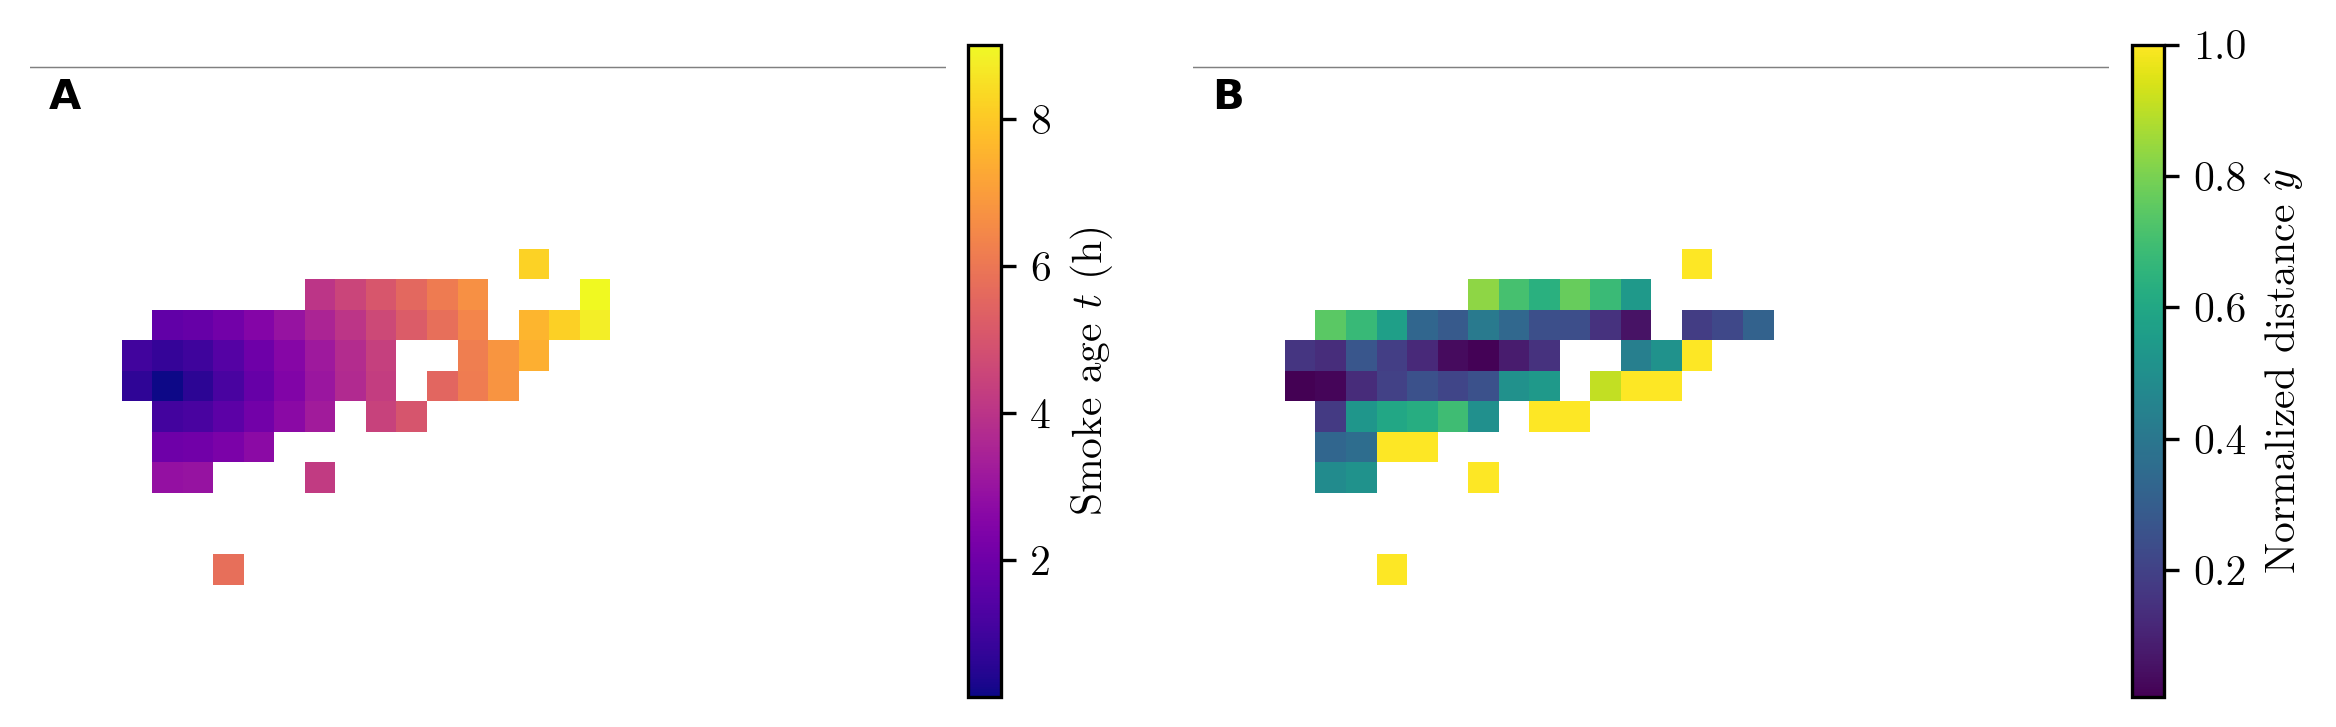

In [6]:
%matplotlib inline

from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

NC = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/tropomi_williams_20190803.nc")
ds = xr.open_dataset(NC)
co = ds["CO_column_number_density"]
if float(np.nanmedian(co)) < 1e6:
    co = co * 1e15
plume = co > 3e18

lon, lat = np.meshgrid(ds.longitude.values, ds.latitude.values)
proj = ccrs.PlateCarree()
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), subplot_kw={"projection": proj}, dpi=300)
countries = cfeature.NaturalEarthFeature("cultural", "admin_0_countries", "50m", facecolor="none")
fields = [
    (ds["t"].where(plume), "plasma", r"Smoke age $t$ (h)"),
    (ds["yhat"].where(plume), "viridis", r"Normalized distance $\hat{y}$"),
]
for ax, (field, cmap, label) in zip(axes, fields):
    ax.set_extent([-119, -116, 47, 49], crs=proj)
    ax.add_feature(countries, edgecolor="gray", linewidth=0.3)
    ax.set_axis_off()
    artist = ax.pcolormesh(lon, lat, field, cmap=cmap, transform=proj)
    bar = fig.colorbar(artist, ax=ax, shrink=0.75, pad=0.02)
    bar.set_label(label)
for letter, ax in zip("AB", axes):
    ax.text(0.02, 0.98, letter, transform=ax.transAxes, ha="left", va="top", fontweight="bold", fontfamily="Arial")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs03.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs03.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
